In [2]:

# Verify confusion matrix calculation
metrics = model.val(
    data=str(dataset),
    split="val",
    imgsz=640,
    batch=4,
    device="mps",
    workers=0,
    conf=0.25,
    iou=0.7,
    plots=True,  # Important: enable confusion matrix updates
    project=str(ROOT / "runs/evaluation"),
    name="e02_conf025_fixed",
    exist_ok=False,
)

cm = metrics.confusion_matrix.matrix

print("Confusion Matrix:")
print(cm)

print("\nTP:", int(cm[0, 0]))
print("FP:", int(cm[0, 1]))
print("FN:", int(cm[1, 0]))

assert cm.sum() > 0, "Confusion matrix is empty!"


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 512.6±188.7 MB/s, size: 128.0 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 93.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 25.4it/s 2.9s0.1s
                   all        291       1843      0.866      0.793      0.811      0.443
Speed: 0.3ms preprocess, 1.1ms inference, 0.0ms loss, 3.4ms postprocess per image
Results saved to /Users/luzhang/COMP9517/comp9517-bird-detection/runs/evaluation/e02_conf025_fixed
Confusion Matrix:
[[       1595         451]
 [        248           0]]

TP: 1595
FP: 451
FN: 248


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 351.7±132.0 MB/s, size: 142.5 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 61.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 23.7it/s 3.1s0.2s
                   all        291       1843      0.866      0.793      0.855      0.462
Speed: 0.3ms preprocess, 1.3ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /Users/luzhang/COMP9517/comp9517-bird-detection/runs/evaluation/e02_threshold_05
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs

,Confidence,TP,FP,FN,Precision,Recall,F1
0,0.05,1712,2158,131,0.4424,0.9289,0.5993
1,0.10,1684,1280,159,0.5682,0.9137,0.7006
2,0.25,1595,451,248,0.7796,0.8654,0.8203
3,0.50,1351,86,492,0.9402,0.7330,0.8238


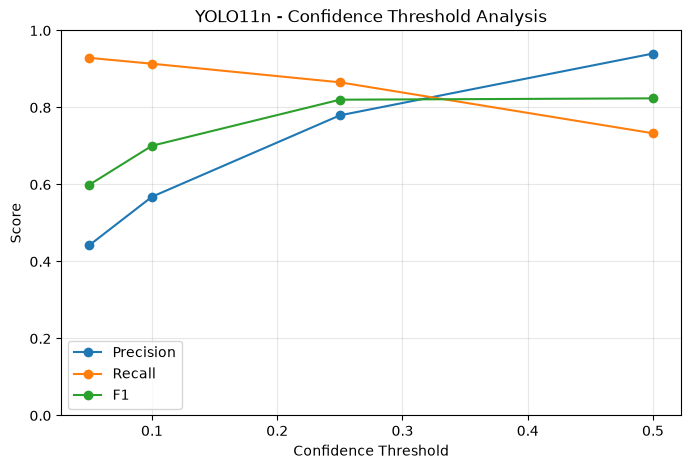

In [3]:

import pandas as pd
import matplotlib.pyplot as plt

thresholds = [0.05, 0.10, 0.25, 0.50]
records = []

for conf in thresholds:
    metrics = model.val(
        data=str(dataset),
        split="val",
        imgsz=640,
        batch=4,
        device="mps",
        workers=0,
        conf=conf,
        iou=0.7,
        plots=True,
        project=str(ROOT / "runs/evaluation"),
        name=f"e02_threshold_{int(conf * 100):02d}",
        exist_ok=False,
    )

    cm = metrics.confusion_matrix.matrix

    tp, fp, fn = int(cm[0, 0]), int(cm[0, 1]), int(cm[1, 0])

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0

    records.append({
        "Confidence": conf,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    })

threshold_df = pd.DataFrame(records)
display(threshold_df.round(4))

# Save experimental results
threshold_df.to_csv(
    ROOT / "runs/evaluation/e02_threshold_sweep.csv",
    index=False
)

# Visualization
plt.figure(figsize=(8, 5))

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(
        threshold_df["Confidence"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title("YOLO11n - Confidence Threshold Analysis")
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [4]:

import time
import pandas as pd

resolution_results = []

for imgsz in [640, 960]:
    start = time.perf_counter()

    metrics = model.val(
        data=str(dataset),
        split="val",
        imgsz=imgsz,
        conf=0.001,
        iou=0.7,
        batch=4,
        device="mps",
        workers=0,
        plots=False,
        project=str(ROOT / "runs/evaluation"),
        name=f"e02_resolution_{imgsz}",
        exist_ok=False,
    )

    elapsed = time.perf_counter() - start

    resolution_results.append({
        "Resolution": imgsz,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "Inference (ms/image)": metrics.speed["inference"],
        "Validation Wall Time (s)": elapsed,
    })

resolution_df = pd.DataFrame(resolution_results)

display(resolution_df.round(4))

resolution_df.to_csv(
    ROOT / "runs/evaluation/e02_resolution_comparison.csv",
    index=False
)


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 390.2±64.1 MB/s, size: 90.6 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 101.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 73/73 27.8it/s 2.6s0.1s
                   all        291       1843      0.866      0.793      0.868      0.471
Speed: 0.3ms preprocess, 1.1ms inference, 0.0ms loss, 3.6ms postprocess per image
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5439.6±808.2 MB/s, size: 134.0 KB)
val: Scanning

,Resolution,Precision,Recall,mAP50,mAP50-95,Inference (ms/image),Validation Wall Time (s)
0,640,0.8661,0.7932,0.8679,0.4708,1.1225,3.0431
1,960,0.8609,0.7770,0.8493,0.4544,2.1009,4.6087


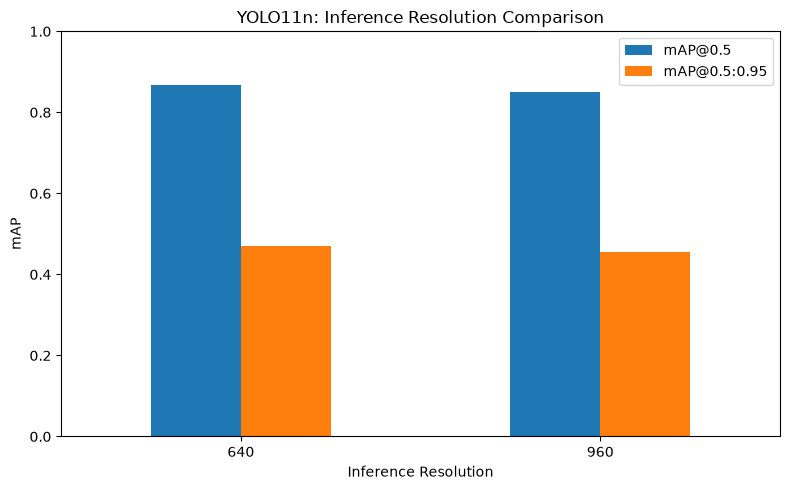

In [5]:

import matplotlib.pyplot as plt

# Compare mAP at different inference resolutions
ax = resolution_df.plot(
    x="Resolution",
    y=["mAP50", "mAP50-95"],
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("YOLO11n: Inference Resolution Comparison")
ax.set_xlabel("Inference Resolution")
ax.set_ylabel("mAP")
ax.set_ylim(0, 1)
ax.legend(["mAP@0.5", "mAP@0.5:0.95"])

plt.tight_layout()

plt.savefig(
    ROOT / "runs/evaluation/e02_resolution_comparison.png",
    dpi=200
)
plt.show()
